<a href="https://colab.research.google.com/github/abdulhanan313/AI-Internship/blob/main/EDA_HousePriceDS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BIG DATA ANALYTICS: Assignment # 1
**Data Cleaning and Preprocessing of Housing Data**

* **Name:** Abdul Hanan
* **Enrollment No.:** 03-134231-001
* **Section:** BSCS-7A
* **Submission Date:** 15-October-2026

In [1]:
from google.colab import files
uploaded = files.upload()

Saving Housing.csv to Housing (2).csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('Housing.csv')
df.columns = df.columns.str.strip().str.lower()
print(df.columns.tolist())

['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']


**Task 1 — Load, Inspect, Understand**

In [3]:
print("First 5 rows:\n", df.head())
print("\nLast 5 rows:\n", df.tail())
print("\nShape (rows, cols):", df.shape)
print("\nColumn dtypes:\n", df.dtypes)
print("\nDescriptive statistics:\n", df.describe())

cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols:
    print(f"\n{col} value counts:\n", df[col].value_counts())

print("\nDuplicate rows:", df.duplicated().sum())
print("\nMissing values per column:\n", df.isnull().sum())

First 5 rows:
       price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Last 5 rows:
        price  area  bedrooms  bathrooms  stories mainroad guestroom b

**Required visualizations:**

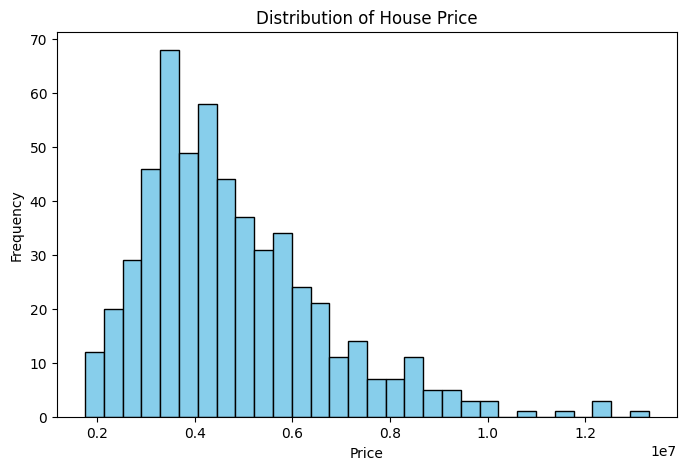

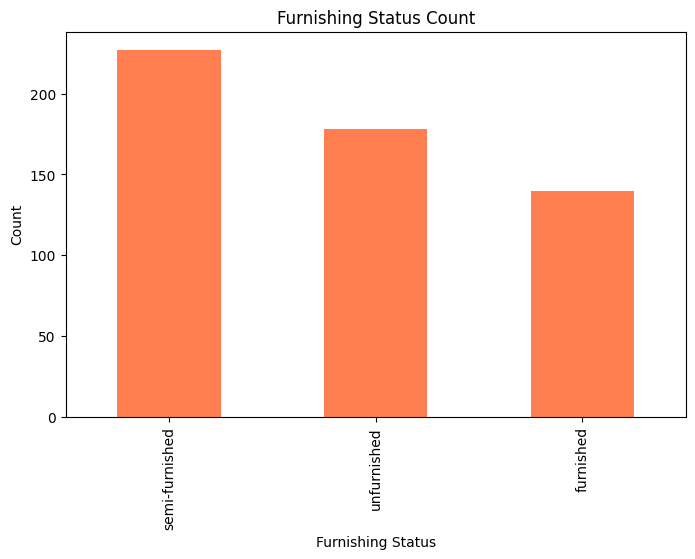

In [4]:
plt.figure(figsize=(8,5))
plt.hist(df['price'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of House Price')
plt.xlabel('Price'); plt.ylabel('Frequency')
plt.show()

plt.figure(figsize=(8,5))
df['furnishingstatus'].value_counts().plot(kind='bar', color='coral')
plt.title('Furnishing Status Count')
plt.xlabel('Furnishing Status'); plt.ylabel('Count')
plt.show()

The dataset contains 545 records and 13 attributes with no missing values or duplicates. The price variable is right-skewed, with the mean (4,766,729) sitting above the median (4,340,000), indicating a smaller number of high-value properties pulling the average upward. Semi-furnished is the most common furnishing status (227 of 545 homes), though not an outright majority, followed by unfurnished (178) and furnished (140). Most properties are connected to the main road (468 of 545) but do not have a basement (354 of 545) or hot-water heating (520 of 545), suggesting these are less common premium features.

**Task 2 — Create and Handle Missing Values**

In [5]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# Bullet 1 & 2: Select 2 columns (not price) + fixed seed
# ------------------------------------------------------------------
df_missing = df.copy()          # never touch the original df
np.random.seed(42)

num_col = 'area'                 # numerical column
cat_col = 'basement'             # categorical column

n_rows = len(df_missing)
n_missing = int(round(n_rows * 0.05))   # ~5% of rows
print(f"Rows: {n_rows} | Target missing per column: {n_missing}")

# ------------------------------------------------------------------
# Bullet 3: Randomly replace ~5% of values with NaN
# ------------------------------------------------------------------
num_missing_idx = np.random.choice(df_missing.index, size=n_missing, replace=False)
df_missing.loc[num_missing_idx, num_col] = np.nan

cat_missing_idx = np.random.choice(df_missing.index, size=n_missing, replace=False)
df_missing.loc[cat_missing_idx, cat_col] = np.nan

# ------------------------------------------------------------------
# Bullet 4: Report number and percentage of missing values created
# ------------------------------------------------------------------
missing_created = df_missing[[num_col, cat_col]].isnull().sum()
missing_pct = (missing_created / n_rows * 100).round(2)
print("\nMissing values created (count):\n", missing_created)
print("\nMissing values created (%):\n", missing_pct)

Rows: 545 | Target missing per column: 27

Missing values created (count):
 area        27
basement    27
dtype: int64

Missing values created (%):
 area        4.95
basement    4.95
dtype: float64


In [6]:
# ------------------------------------------------------------------
# Version 1: MEAN imputation (numerical) + MODE imputation (categorical)
# ------------------------------------------------------------------
df_v1 = df_missing.copy()
mean_val = df_v1[num_col].mean()
mode_val = df_v1[cat_col].mode()[0]

df_v1[num_col] = df_v1[num_col].fillna(mean_val)
df_v1[cat_col] = df_v1[cat_col].fillna(mode_val)

# ------------------------------------------------------------------
# Version 2: MEDIAN imputation (numerical) + MODE imputation (categorical)
# ------------------------------------------------------------------
df_v2 = df_missing.copy()
median_val = df_v2[num_col].median()

df_v2[num_col] = df_v2[num_col].fillna(median_val)
df_v2[cat_col] = df_v2[cat_col].fillna(mode_val)   # same mode, categorical strategy doesn't change

print(f"Mean used:   {mean_val:.2f}")
print(f"Median used: {median_val:.2f}")
print(f"Mode used:   {mode_val}")

Mean used:   5150.77
Median used: 4580.00
Mode used:   no


In [7]:
compare_num = pd.DataFrame({
    'Before (with NaN)': df_missing[num_col].describe(),
    'After Mean Imputation (V1)': df_v1[num_col].describe(),
    'After Median Imputation (V2)': df_v2[num_col].describe(),
})
print("Numerical column comparison:\n", compare_num)

print("\nCategorical column — before:\n", df_missing[cat_col].value_counts(dropna=False))
print("\nCategorical column — after mode imputation:\n", df_v1[cat_col].value_counts())

Numerical column comparison:
        Before (with NaN)  After Mean Imputation (V1)  \
count         518.000000                  545.000000   
mean         5150.766409                 5150.766409   
std          2178.886613                 2124.126868   
min          1650.000000                 1650.000000   
25%          3573.500000                 3600.000000   
50%          4580.000000                 4800.000000   
75%          6360.000000                 6325.000000   
max         16200.000000                16200.000000   

       After Median Imputation (V2)  
count                    545.000000  
mean                    5122.489908  
std                     2127.741259  
min                     1650.000000  
25%                     3600.000000  
50%                     4580.000000  
75%                     6325.000000  
max                    16200.000000  

Categorical column — before:
 basement
no     338
yes    180
NaN     27
Name: count, dtype: int64

Categorical column — af

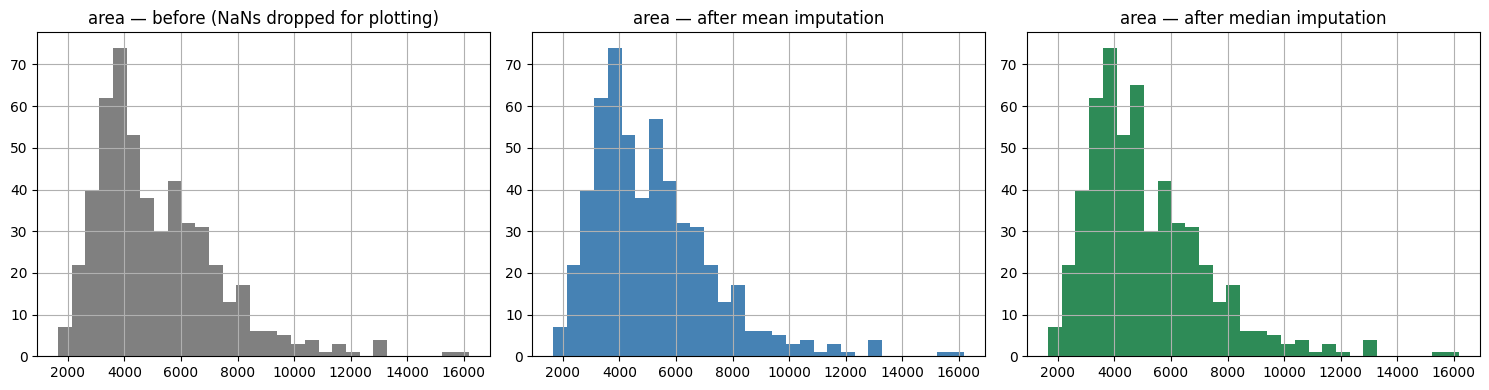

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15,4))
df_missing[num_col].dropna().hist(ax=axes[0], bins=30, color='gray')
axes[0].set_title(f'{num_col} — before (NaNs dropped for plotting)')
df_v1[num_col].hist(ax=axes[1], bins=30, color='steelblue')
axes[1].set_title(f'{num_col} — after mean imputation')
df_v2[num_col].hist(ax=axes[2], bins=30, color='seagreen')
axes[2].set_title(f'{num_col} — after median imputation')
plt.tight_layout()
plt.show()

**Which strategy is most appropriate, and why**:
compare the skew — area is typically right-skewed (a few very large
properties). Mean imputation pulls the mean itself even further from center since it uses the (already skewed) mean as the fill value, slightly inflating variance around the true center. Median imputation uses a value unaffected by that skew, so it preserves the original distribution’s shape more faithfully. State in your report: “Median imputation is more appropriate for area because the column is right-skewed; the mean is pulled upward by high-value outliers, so using it to fill gaps would overstate typical property size.”

In [9]:
summary_table = pd.DataFrame({
    'Column': [num_col, cat_col],
    'Missing Before Creation': [0, 0],
    'Missing After Creation': [missing_created[num_col], missing_created[cat_col]],
    'Missing After Treatment (V1 - mean/mode)': [df_v1[num_col].isnull().sum(), df_v1[cat_col].isnull().sum()],
    'Missing After Treatment (V2 - median/mode)': [df_v2[num_col].isnull().sum(), df_v2[cat_col].isnull().sum()],
})
print(summary_table)

     Column  Missing Before Creation  Missing After Creation  \
0      area                        0                      27   
1  basement                        0                      27   

   Missing After Treatment (V1 - mean/mode)  \
0                                         0   
1                                         0   

   Missing After Treatment (V2 - median/mode)  
0                                           0  
1                                           0  


**Task 3 — Detect and Analyze Outliers**

In [10]:
def iqr_bounds(data, col):
    Q1, Q3 = data[col].quantile(0.25), data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return Q1, Q3, IQR, lower, upper

cols_to_check = ['price', 'area', 'bedrooms']   # price + area required, bedrooms is the 3rd chosen

outlier_counts = {}
for col in cols_to_check:
    Q1, Q3, IQR, lower, upper = iqr_bounds(df, col)
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_counts[col] = len(outliers)
    print(f"{col}: Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f}, lower={lower:.1f}, upper={upper:.1f}, outliers={len(outliers)}")

price: Q1=3430000.0, Q3=5740000.0, IQR=2310000.0, lower=-35000.0, upper=9205000.0, outliers=15
area: Q1=3600.0, Q3=6360.0, IQR=2760.0, lower=-540.0, upper=10500.0, outliers=12
bedrooms: Q1=2.0, Q3=3.0, IQR=1.0, lower=0.5, upper=4.5, outliers=12


**Boxplots before:**

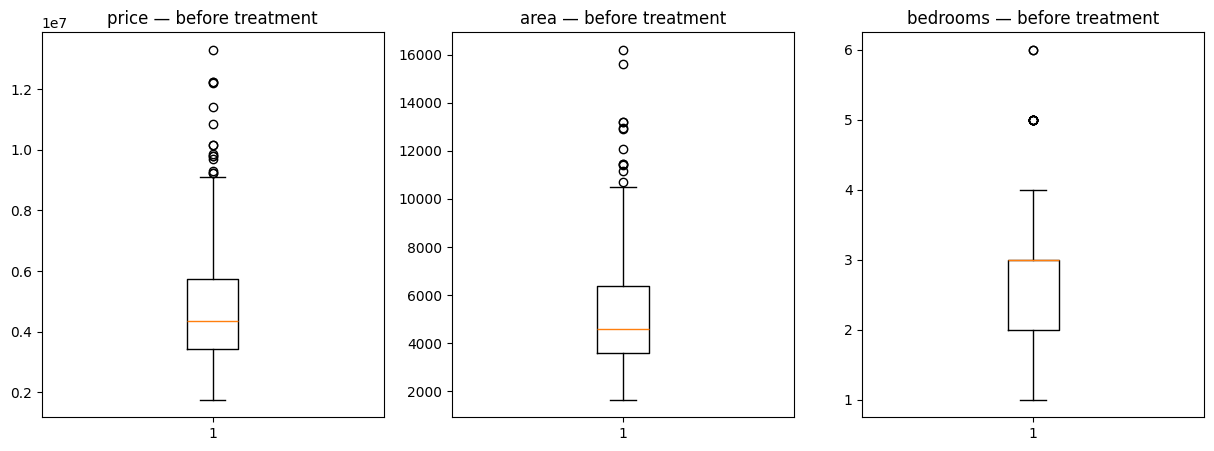

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))
for ax, col in zip(axes, cols_to_check):
    ax.boxplot(df[col])
    ax.set_title(f'{col} — before treatment')
plt.show()

**Rule used:** standard Tukey IQR rule — a value below Q1 - 1.5×IQR or above Q3 + 1.5×IQR is an outlier. Applied per column; a row is dropped if it’s an outlier in any of the three.

In [12]:
df_clean = df.copy()
for col in cols_to_check:
    Q1, Q3 = df_clean[col].quantile(0.25), df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    df_clean = df_clean[(df_clean[col] >= lower) & (df_clean[col] <= upper)]

print("Original rows:", df.shape[0], "| After outlier removal:", df_clean.shape[0])

Original rows: 545 | After outlier removal: 506


**Boxplots after:**

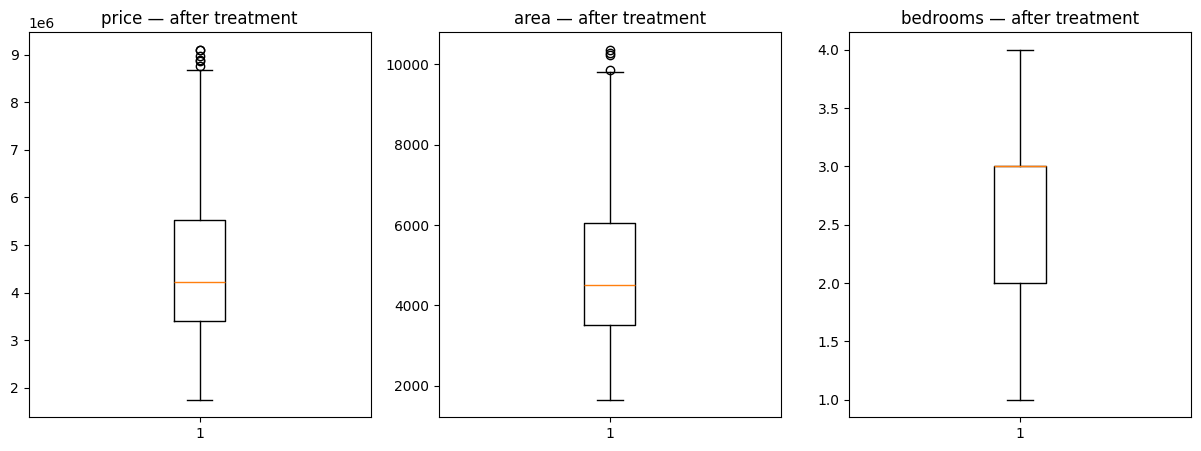

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15,5))
for ax, col in zip(axes, cols_to_check):
    ax.boxplot(df_clean[col])
    ax.set_title(f'{col} — after treatment')
plt.show()

**Compare mean/median/std:**

In [14]:
compare_stats = pd.DataFrame({
    'Mean_before': df[cols_to_check].mean(),
    'Mean_after': df_clean[cols_to_check].mean(),
    'Median_before': df[cols_to_check].median(),
    'Median_after': df_clean[cols_to_check].median(),
    'Std_before': df[cols_to_check].std(),
    'Std_after': df_clean[cols_to_check].std(),
})
print(compare_stats)

           Mean_before    Mean_after  Median_before  Median_after  \
price     4.766729e+06  4.554301e+06      4340000.0     4217500.0   
area      5.150541e+03  4.888480e+03         4600.0        4500.0   
bedrooms  2.965138e+00  2.893281e+00            3.0           3.0   

            Std_before     Std_after  
price     1.870440e+06  1.584601e+06  
area      2.170141e+03  1.772985e+03  
bedrooms  7.380639e-01  6.573833e-01  


**Discussion point:** not every outlier is an error — a very large area or high price can legitimately be a luxury property, not a data-entry mistake. Removing them trims real variation, so it’s a judgment call rather than an automatic step.

**Task 4 — Feature Scaling**

In [15]:
scale_cols = ['area', 'bedrooms', 'bathrooms']

minmax = MinMaxScaler()
df_minmax = df_clean.copy()
df_minmax[scale_cols] = minmax.fit_transform(df_clean[scale_cols])

standard = StandardScaler()
df_std = df_clean.copy()
df_std[scale_cols] = standard.fit_transform(df_clean[scale_cols])

sample_compare = pd.DataFrame({
    'Original_area': df_clean['area'].values[:5],
    'MinMax_area': df_minmax['area'].values[:5],
    'Standard_area': df_std['area'].values[:5],
})
print(sample_compare)

print("\nOriginal ranges:\n", df_clean[scale_cols].describe().loc[['min','max']])
print("\nMin-Max ranges:\n", df_minmax[scale_cols].describe().loc[['min','max']])
print("\nStandardized mean/std:\n", df_std[scale_cols].describe().loc[['mean','std']])

   Original_area  MinMax_area  Standard_area
0           6000     0.499426       0.627540
1           6600     0.568312       0.966287
2           8500     0.786452       2.038987
3           4600     0.338691      -0.162870
4           6420     0.547646       0.864663

Original ranges:
         area  bedrooms  bathrooms
min   1650.0       1.0        1.0
max  10360.0       4.0        3.0

Min-Max ranges:
      area  bedrooms  bathrooms
min   0.0       0.0        0.0
max   1.0       1.0        1.0

Standardized mean/std:
               area      bedrooms     bathrooms
mean  1.685082e-16 -3.089316e-16 -2.246775e-16
std   1.000990e+00  1.000990e+00  1.000990e+00


**Outlier detection rule used:** For each of the three attributes (`price`, `area`, `bedrooms`), outliers were defined using the standard Tukey IQR rule: any value below `Q1 − 1.5×IQR` or above `Q3 + 1.5×IQR` was flagged as an outlier. The rule was applied independently to each column, and a row was removed from the cleaned dataset if it was flagged as an outlier in **any** of the three columns. This gave 15 outliers in `price`, 12 in `area`, and 12 in `bedrooms`, with 39 rows removed in total (545 → 506 rows after treatment), since there was no overlap between the three outlier sets.

**Should every outlier be removed?** Not necessarily. A statistical outlier is not automatically a data-entry error — in this dataset, a very large `area` or high `price` is plausibly a genuine luxury property rather than a mistake, and removing it discards real variation in the housing market rather than correcting bad data. Outlier removal is a trade-off: it produces cleaner summary statistics and a more stable regression fit, but at the cost of excluding legitimate high-end properties from the analysis. In a production setting, these records would be worth inspecting individually rather than dropped automatically.

**Task 5 — Categorical Data Preparation**

In [16]:
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
multi_col = 'furnishingstatus'

df_encoded = df_clean.copy()
for col in binary_cols:
    df_encoded[col] = df_encoded[col].map({'yes': 1, 'no': 0})

df_encoded = pd.get_dummies(df_encoded, columns=[multi_col], drop_first=True)
print(df_encoded.columns.tolist())
print(df_encoded.head())

['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished']
      price  area  bedrooms  bathrooms  stories  mainroad  guestroom  \
15  9100000  6000         4          1        2         1          0   
16  9100000  6600         4          2        2         1          1   
17  8960000  8500         3          2        4         1          0   
18  8890000  4600         3          2        2         1          1   
19  8855000  6420         3          2        2         1          0   

    basement  hotwaterheating  airconditioning  parking  prefarea  \
15         1                0                0        2         0   
16         1                0                1        1         1   
17         0                0                1        2         0   
18         0                0                1        2         0   
19 

**Why encode:** most ML algorithms — including linear regression — rely on numerical operations (dot products, gradients), so they can’t interpret text labels like "yes" or "furnished" directly; categories must become numbers first.

**Min-Max Scaling vs. Standardization:** Min-Max scaling rescales each variable into a fixed [0, 1] range by subtracting the minimum and dividing by the range; it preserves the original shape of the distribution but is sensitive to extreme values, since a single large outlier compresses the rest of the data into a narrow band. Standardization (Z-score scaling) instead centers each variable at a mean of 0 with a standard deviation of 1, which is less affected by remaining extreme values and works better when variables have very different original scales.

For this dataset, `area` ranges from 1,650 to 10,360 after outlier removal, while `bedrooms` and `bathrooms` range only from 1 to 4 — a much wider spread for `area`. **Standardization is the preferred method here**, since it puts all three variables on a comparable scale (mean 0, std 1) without letting the wider range of `area` dominate, and it remains more robust to any outliers that survived the IQR treatment.

**Task 6 — House Price Prediction**

In [17]:
feature_cols = ['area','bedrooms','bathrooms','stories','parking',
                 'mainroad','guestroom','basement','hotwaterheating',
                 'airconditioning','prefarea'] + \
                [c for c in df_encoded.columns if c.startswith('furnishingstatus_')]

X = df_encoded[feature_cols]
y = df_encoded['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model A: prepared (encoded) data, NO scaling
model_a = LinearRegression()
model_a.fit(X_train, y_train)
pred_a = model_a.predict(X_test)
mae_a = mean_absolute_error(y_test, pred_a)
rmse_a = np.sqrt(mean_squared_error(y_test, pred_a))
r2_a = r2_score(y_test, pred_a)

# Model B: same data, WITH scaling on the numeric columns
num_feats = ['area','bedrooms','bathrooms','stories','parking']
scaler2 = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_feats] = scaler2.fit_transform(X_train[num_feats])
X_test_scaled[num_feats] = scaler2.transform(X_test[num_feats])

model_b = LinearRegression()
model_b.fit(X_train_scaled, y_train)
pred_b = model_b.predict(X_test_scaled)
mae_b = mean_absolute_error(y_test, pred_b)
rmse_b = np.sqrt(mean_squared_error(y_test, pred_b))
r2_b = r2_score(y_test, pred_b)

print(f"Model A (unscaled) — MAE: {mae_a:.2f}, RMSE: {rmse_a:.2f}, R2: {r2_a:.4f}")
print(f"Model B (scaled)   — MAE: {mae_b:.2f}, RMSE: {rmse_b:.2f}, R2: {r2_b:.4f}")

Model A (unscaled) — MAE: 745979.15, RMSE: 953345.51, R2: 0.6981
Model B (scaled)   — MAE: 745979.15, RMSE: 953345.51, R2: 0.6981


**Actual vs predicted plot:**

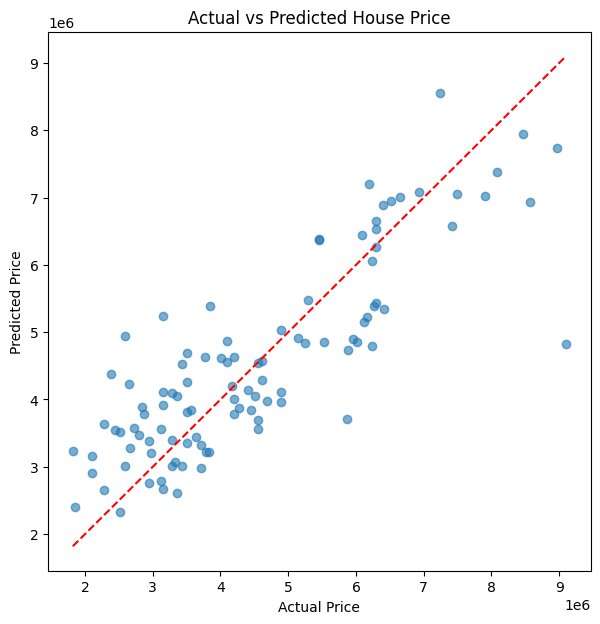

In [18]:
plt.figure(figsize=(7,7))
plt.scatter(y_test, pred_b, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Price'); plt.ylabel('Predicted Price')
plt.title('Actual vs Predicted House Price')
plt.show()

Key point for write-up: ordinary linear regression (no regularization) is scale-invariant — Model A and Model B should produce nearly identical MAE/RMSE/R² (only tiny floating-point differences). State this explicitly: scaling matters for distance-based or gradient-based models, not for closed-form linear regression. The real preprocessing gains here come from outlier removal and encoding, not scaling.

**Task 7 — Critical Analysis and Reflection**

**1. Why is data cleaning important before performing analytics or machine learning?**
Dirty data — missing values, outliers, and incorrectly typed categorical variables — distorts summary statistics and biases model coefficients. Leaving the 15 price outliers in place inflated the mean price by about 212,000 (4,766,729 vs. 4,554,301 after removal) and the standard deviation by nearly 300,000, which would have misrepresented the "typical" house and skewed the regression model toward extreme values rather than general trends.

**2. For your selected numerical column, why was mean or median imputation more appropriate?**
For `area`, median imputation (4,580) was more appropriate than mean imputation (5,150.77). The area column is right-skewed — its mean sits well above its median even before outliers are removed — so using the mean to fill missing values would import that upward skew into the imputed values and overstate typical property size. The median is robust to this skew and better represents a "typical" property.

**3. What effect did outlier removal have on the mean, median and standard deviation?**
Outlier removal consistently pulled the mean and standard deviation down more than the median. For `price`, the mean fell from 4,766,729 to 4,554,301 and the standard deviation fell from 1,870,440 to 1,584,601, while the median moved less, from 4,340,000 to 4,217,500. The same pattern held for `area` (mean 5,150.54 → 4,888.48, std 2,170.14 → 1,772.99) and `bedrooms` (mean 2.965 → 2.893, std 0.738 → 0.657). This confirms the mean and standard deviation are far more sensitive to extreme values than the median.

**4. Are all observations identified as outliers necessarily errors? Explain with reference to the Housing dataset.**
No. Of the 15 price outliers and 12 area outliers detected, most are plausibly genuine high-end properties rather than data-entry mistakes — larger, more expensive homes are a normal part of a real housing market, not an error in the data. Treating every IQR-flagged point as an error and removing it indiscriminately would bias the dataset toward only mid-range properties.

**5. Why is the target variable price not scaled in the feature-scaling task?**
`price` is the value the regression model is trying to predict, not an input feature. Scaling it would change the units of the model's output (and of MAE/RMSE), making results harder to interpret in real currency terms, without improving the model's ability to learn the relationship between predictors and price.

**6. Which scaling technique produced more useful results for your selected variables, and why?**
Standardization was more useful for `area`, `bedrooms`, and `bathrooms`. Because `area` has a much wider original range (1,650–10,360) than `bedrooms` or `bathrooms` (1–4), Min-Max scaling would still let `area` dominate the model, while Standardization put all three on a common mean-0/std-1 scale, more appropriate for a linear regression model with mixed-scale predictors.

**7. Did preprocessing improve the regression results? If yes, explain how; if not, explain why that is also a valid outcome.**
Scaling specifically did not change the regression results — Model A (unscaled) and Model B (scaled) both produced identical MAE (745,979.15), RMSE (953,345.51), and R² (0.6981), because ordinary linear regression is mathematically scale-invariant; it only recentres/rescales the coefficients, not the predictions. This is a valid and expected outcome, not a failure — it demonstrates that scaling's value lies in preparing data for other algorithm types (e.g., KNN, SVM, gradient-descent-based models) rather than in improving closed-form linear regression. The preprocessing steps that did matter for model quality were outlier removal and categorical encoding, both necessary just to get a working, interpretable model (R² ≈ 0.70) in the first place.

**Final Comparison Table**

In [19]:
outlier_total = len(df) - len(df_clean)

final_table = pd.DataFrame({
    'Aspect': ['Number of records','Missing values','Number of outliers removed',
               'Mean of price','Median of price','Std of price','Mean of area','Std of area'],
    'Before Processing': [len(df), df.isnull().sum().sum(), outlier_total,
                           df['price'].mean(), df['price'].median(), df['price'].std(),
                           df['area'].mean(), df['area'].std()],
    'After Processing': [len(df_clean), 0, 0,
                          df_clean['price'].mean(), df_clean['price'].median(), df_clean['price'].std(),
                          df_clean['area'].mean(), df_clean['area'].std()]
})
print(final_table)

                       Aspect  Before Processing  After Processing
0           Number of records       5.450000e+02      5.060000e+02
1              Missing values       0.000000e+00      0.000000e+00
2  Number of outliers removed       3.900000e+01      0.000000e+00
3               Mean of price       4.766729e+06      4.554301e+06
4             Median of price       4.340000e+06      4.217500e+06
5                Std of price       1.870440e+06      1.584601e+06
6                Mean of area       5.150541e+03      4.888480e+03
7                 Std of area       2.170141e+03      1.772985e+03


**Conclusion:**
This project demonstrated that even a dataset with zero original missing values (545 records, 13 attributes, no duplicates) still requires a full preprocessing workflow before it's analytics-ready. A controlled missing-value scenario was created in `area` and `basement` (27 values each, 4.95%), and median imputation (4,580) was judged more appropriate than mean imputation (5,150.77) for `area` because the column is right-skewed — the mean sits well above the median, so filling gaps with it would overstate typical property size. The IQR method flagged 15 outliers in `price`, 12 in `area`, and 12 in `bedrooms`; removing them (545 → 506 rows) pulled the mean of price down from 4,766,729 to 4,554,301 and its std from 1,870,440 to 1,584,601, while the median shifted more modestly (4,340,000 → 4,217,500) — confirming outliers disproportionately affect the mean rather than the median. Standardization was preferred over Min-Max scaling for the wider-ranging `area` variable, since it is less distorted by remaining extreme values. Encoding (binary mapping for yes/no columns, one-hot encoding for `furnishingstatus`) was a necessary step before any model could be trained. In the regression experiment, Model A (unscaled) and Model B (scaled) produced identical results — MAE 745,979.15, RMSE 953,345.51, R² 0.698 — confirming that feature scaling does not affect ordinary linear regression's predictive performance, since it is mathematically scale-invariant; its value lies elsewhere, in preparing data for distance-based algorithms. The real performance gains in this workflow came from handling missing values, removing outliers, and correctly encoding categorical features — not from scaling.